In [36]:
import math
from collections import namedtuple

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


l = math.pi
T = 2

a = 1
b = 0
g = 0

alpha, beta = 1, 0
gamma, delta = 1, 0

N = 200
sigma = 0.4

phi_0 = lambda t: np.exp(-0.5 * t)
phi_l = lambda t: -np.exp(-0.5 * t)
psi = lambda x: np.sin(x)
f = lambda x, t: 0.5 * np.exp(-0.5 * t) * np.sin(x)
u_exact = lambda x, t: np.exp(-0.5 * t) * np.sin(x)

$
\begin{cases}
\dfrac{\partial u}{\partial t} = \dfrac{\partial^2 u}{\partial x^2} + 0.5\,e^{-0.5t}\sin x, \quad 0 < x < \pi,\ t > 0, \\
u_x(0, t) = e^{-0.5t}, \\
u_x(\pi, t) = -e^{-0.5t}, \\
u(x, 0) = \sin x,
\end{cases}
\qquad
U(x, t) = e^{-0.5t}\sin x
$

Общая постановка:

$
\dfrac{\partial u}{\partial t} = a^2\dfrac{\partial^2 u}{\partial x^2} + b\dfrac{\partial u}{\partial x} + gu + f(x, t), \qquad
\alpha u_x(0,t) + \beta u(0,t) = \varphi_0(t), \qquad
\gamma u_x(l,t) + \delta u(l,t) = \varphi_l(t), \qquad
u(x, 0) = \psi(x),
$

$a = 1$, $b = 0$, $g = 0$, $l = \pi$, $\alpha = 1$, $\beta = 0$, $\varphi_0(t) = e^{-0.5t}$, $\gamma = 1$, $\delta = 0$, $\varphi_l(t) = -e^{-0.5t}$, $\psi(x) = \sin x$.

Слагаемое $f(x, t) = 0.5\,e^{-0.5t}\sin x$ не содержит $u$, поэтому во всех схемах оно будет известным свободным членом. Граничные условия второго рода — частный случай условий третьего рода при $\beta = \delta = 0$.

## Конечно-разностная сетка

Нанесём на область $0 \le x \le l$, $0 \le t \le T$ сетку:

$
\omega_{h\tau} = \{x_j = jh,\ j = \overline{0, N};\ t^k = k\tau,\ k = \overline{0, K}\}, \qquad h = \dfrac{l}{N}, \quad \tau = \dfrac{T}{K}.
$

На нижнем слое $t^k$ сеточная функция $u_j^k$ известна (при $k = 0$ — из начального условия $u_j^0 = \psi(x_j)$), на верхнем слое $t^{k+1}$ её нужно найти.

Погрешность на слое $t^k$: $\varepsilon^k = \max_j |u_j^k - U(x_j, t^k)|$.

Граничным условиям на каждом шаге нужны время верхнего слоя $t^{k+1}$, шаги $h$, $\tau$ и решение на нижнем слое $u^k$ (последнее — только двухточечной аппроксимации второго порядка). Передаём их одним объектом `TimeStep(t_next, h, tau, u_prev)`.

In [37]:
def make_grid(N, K):
    x = np.linspace(0, l, N + 1)
    t = np.linspace(0, T, K + 1)

    return x, t, l / N, T / K


def steps_for_sigma(N, sigma):
    h = l / N
    return math.ceil(T * a * a / (sigma * h * h))


def error(x, t, u):
    return np.max(np.abs(u - u_exact(x[None, :], t[:, None])), axis=1)


TimeStep = namedtuple('TimeStep', ['t_next', 'h', 'tau', 'u_prev'])

# 1. Явная конечно-разностная схема

## Внутренние узлы

Аппроксимируем производную по времени разностью вперёд, а вторую производную по $x$ — центральной разностью на **нижнем** временном слое:

$
\left.\dfrac{\partial u}{\partial t}\right|_j^k = \dfrac{u_j^{k+1} - u_j^k}{\tau} + O(\tau), \qquad
\left.\dfrac{\partial^2 u}{\partial x^2}\right|_j^k = \dfrac{u_{j+1}^k - 2u_j^k + u_{j-1}^k}{h^2} + O(h^2).
$

Подставляя их в уравнение, получаем явную схему:

$
\dfrac{u_j^{k+1} - u_j^k}{\tau} = a^2\dfrac{u_{j+1}^k - 2u_j^k + u_{j-1}^k}{h^2} + f(x_j, t^k) + O(\tau + h^2), \qquad j = \overline{1, N-1}.
$

В каждом уравнении неизвестно только $u_j^{k+1}$, поэтому оно выражается явно:

$
u_j^{k+1} = \sigma u_{j+1}^k + (1 - 2\sigma)u_j^k + \sigma u_{j-1}^k + \tau f(x_j, t^k), \qquad \sigma = \dfrac{a^2\tau}{h^2}.
$

Схема условно устойчива: требуется $\sigma \le \dfrac{1}{2}$, то есть $\tau \le \dfrac{h^2}{2a^2}$.

## Граничные узлы

Формула даёт только $u_1^{k+1}, \dots, u_{N-1}^{k+1}$. Значения $u_0^{k+1}$ и $u_N^{k+1}$ находим после этого из граничных условий, аппроксимированных на верхнем слое. Рассмотрим три способа аппроксимации.

### Двухточечная аппроксимация с первым порядком

Заменим производные направленными разностями:

$
\left.\dfrac{\partial u}{\partial x}\right|_{j=0}^{k+1} = \dfrac{u_1^{k+1} - u_0^{k+1}}{h} + O(h), \qquad
\left.\dfrac{\partial u}{\partial x}\right|_{j=N}^{k+1} = \dfrac{u_N^{k+1} - u_{N-1}^{k+1}}{h} + O(h).
$

Граничные условия принимают вид

$
\alpha\dfrac{u_1^{k+1} - u_0^{k+1}}{h} + \beta u_0^{k+1} = \varphi_0(t^{k+1}), \qquad
\gamma\dfrac{u_N^{k+1} - u_{N-1}^{k+1}}{h} + \delta u_N^{k+1} = \varphi_l(t^{k+1}),
$

$
u_0^{k+1} = -\dfrac{\alpha/h}{\beta - \alpha/h}u_1^{k+1} + \dfrac{\varphi_0(t^{k+1})}{\beta - \alpha/h}, \qquad
u_N^{k+1} = \dfrac{\gamma/h}{\delta + \gamma/h}u_{N-1}^{k+1} + \dfrac{\varphi_l(t^{k+1})}{\delta + \gamma/h}.
$

In [38]:
def explicit_boundary_two_point_first_order(u_new, time_step):
    t_next, h = time_step.t_next, time_step.h

    u_0 = -(alpha / h) / (beta - alpha / h) * u_new[1] + phi_0(t_next) / (beta - alpha / h)
    u_N = (gamma / h) / (delta + gamma / h) * u_new[-2] + phi_l(t_next) / (delta + gamma / h)

    return u_0, u_N

### Трёхточечная аппроксимация со вторым порядком

Используем формулы численного дифференцирования второго порядка:

$
\dfrac{\partial u}{\partial x}(0, t^{k+1}) = \dfrac{-3u_0^{k+1} + 4u_1^{k+1} - u_2^{k+1}}{2h} + O(h^2), \qquad
\dfrac{\partial u}{\partial x}(l, t^{k+1}) = \dfrac{u_{N-2}^{k+1} - 4u_{N-1}^{k+1} + 3u_N^{k+1}}{2h} + O(h^2).
$

В явной схеме $u_1^{k+1}, u_2^{k+1}, u_{N-2}^{k+1}, u_{N-1}^{k+1}$ к этому моменту уже известны, поэтому алгоритм принципиально не меняется:

$
u_0^{k+1} = \dfrac{\varphi_0(t^{k+1}) - \alpha\dfrac{4u_1^{k+1} - u_2^{k+1}}{2h}}{\beta - \dfrac{3\alpha}{2h}}, \qquad
u_N^{k+1} = \dfrac{\varphi_l(t^{k+1}) - \gamma\dfrac{u_{N-2}^{k+1} - 4u_{N-1}^{k+1}}{2h}}{\delta + \dfrac{3\gamma}{2h}}.
$

In [39]:
def explicit_boundary_three_point_second_order(u_new, time_step):
    t_next, h = time_step.t_next, time_step.h

    u_0 = (phi_0(t_next) - alpha * (4 * u_new[1] - u_new[2]) / (2 * h)) / (beta - 3 * alpha / (2 * h))
    u_N = (phi_l(t_next) - gamma * (u_new[-3] - 4 * u_new[-2]) / (2 * h)) / (delta + 3 * gamma / (2 * h))

    return u_0, u_N

### Двухточечная аппроксимация со вторым порядком

Повысим порядок, не добавляя узлов. Разложим $u_1^{k+1}$ и $u_{N-1}^{k+1}$ в ряд Тейлора в окрестности граничных узлов:

$
u_1^{k+1} = u_0^{k+1} + \left.\dfrac{\partial u}{\partial x}\right|_0^{k+1} h + \left.\dfrac{\partial^2 u}{\partial x^2}\right|_0^{k+1}\dfrac{h^2}{2} + O(h^3), \qquad
u_{N-1}^{k+1} = u_N^{k+1} - \left.\dfrac{\partial u}{\partial x}\right|_N^{k+1} h + \left.\dfrac{\partial^2 u}{\partial x^2}\right|_N^{k+1}\dfrac{h^2}{2} + O(h^3).
$

Вторую производную в граничных узлах выразим из самого уравнения:

$
\dfrac{\partial^2 u}{\partial x^2} = \dfrac{1}{a^2}\left(\dfrac{\partial u}{\partial t} - b\dfrac{\partial u}{\partial x} - gu - f\right).
$

Отсюда первая производная в граничных узлах с порядком $O(h^2)$ (источник входит вместе с $\partial u / \partial t$):

$
\left.\dfrac{\partial u}{\partial x}\right|_0^{k+1} = \dfrac{2a^2}{h(2a^2 - bh)}(u_1^{k+1} - u_0^{k+1}) - \dfrac{h}{2a^2 - bh}\left(\left.\dfrac{\partial u}{\partial t}\right|_0^{k+1} - f_0^{k+1}\right) + \dfrac{gh}{2a^2 - bh}u_0^{k+1},
$

$
\left.\dfrac{\partial u}{\partial x}\right|_N^{k+1} = \dfrac{2a^2}{h(2a^2 + bh)}(u_N^{k+1} - u_{N-1}^{k+1}) + \dfrac{h}{2a^2 + bh}\left(\left.\dfrac{\partial u}{\partial t}\right|_N^{k+1} - f_N^{k+1}\right) - \dfrac{gh}{2a^2 + bh}u_N^{k+1}.
$

Подставим это в граничные условия и заменим $\left.\dfrac{\partial u}{\partial t}\right|_{0,N}^{k+1} = \dfrac{u_{0,N}^{k+1} - u_{0,N}^k}{\tau}$. Получим уравнения, дополненные слагаемым $hf$:

$
b_0 u_0^{k+1} + c_0 u_1^{k+1} = d_0, \qquad a_N u_{N-1}^{k+1} + b_N u_N^{k+1} = d_N,
$

$
b_0 = \dfrac{2a^2}{h} + \dfrac{h}{\tau} - gh - \dfrac{\beta}{\alpha}(2a^2 - bh), \quad c_0 = -\dfrac{2a^2}{h}, \quad
d_0 = \dfrac{h}{\tau}u_0^k - \varphi_0(t^{k+1})\dfrac{2a^2 - bh}{\alpha} + h f_0^{k+1};
$

$
a_N = -\dfrac{2a^2}{h}, \quad b_N = \dfrac{2a^2}{h} + \dfrac{h}{\tau} - gh + \dfrac{\delta}{\gamma}(2a^2 + bh), \quad
d_N = \dfrac{h}{\tau}u_N^k + \varphi_l(t^{k+1})\dfrac{2a^2 + bh}{\gamma} + h f_N^{k+1}.
$

Для явной схемы $u_1^{k+1}$ и $u_{N-1}^{k+1}$ уже известны, поэтому

$
u_0^{k+1} = \dfrac{d_0 + \dfrac{2a^2}{h}u_1^{k+1}}{b_0}, \qquad u_N^{k+1} = \dfrac{d_N + \dfrac{2a^2}{h}u_{N-1}^{k+1}}{b_N}.
$

In [40]:
def explicit_boundary_two_point_second_order(u_new, time_step):
    t_next, h, tau, u_prev = time_step

    b_0 = 2 * a * a / h + h / tau - g * h - beta / alpha * (2 * a * a - b * h)
    d_0 = h / tau * u_prev[0] - phi_0(t_next) * (2 * a * a - b * h) / alpha + h * f(0, t_next)

    b_N = 2 * a * a / h + h / tau - g * h + delta / gamma * (2 * a * a + b * h)
    d_N = h / tau * u_prev[-1] + phi_l(t_next) * (2 * a * a + b * h) / gamma + h * f(l, t_next)

    u_0 = (d_0 + 2 * a * a / h * u_new[1]) / b_0
    u_N = (d_N + 2 * a * a / h * u_new[-2]) / b_N

    return u_0, u_N

## Алгоритм явной схемы

На каждом шаге по времени сначала считаем все внутренние узлы, затем граничные — выбранной аппроксимацией. Решение хранится в матрице `u[k, j]`$= u_j^k$.

In [41]:
def explicit_scheme(bc, N, K):
    x, t, h, tau = make_grid(N, K)
    sigma = a * a * tau / (h * h)

    u = np.zeros((K + 1, N + 1), dtype=np.float64)
    u[0] = psi(x)

    for k in range(K):
        u[k + 1, 1:-1] = (
            sigma * u[k, 2:]
            + (1 - 2 * sigma) * u[k, 1:-1]
            + sigma * u[k, :-2]
            + tau * f(x[1:-1], t[k])
        )

        u[k + 1, 0], u[k + 1, -1] = bc(u[k + 1], TimeStep(t[k + 1], h, tau, u[k]))

    return x, t, u

## Результаты явной схемы

Возьмём $N = 200$ и $\sigma = 0.4 \le 1/2$. Из-за условия устойчивости шаг по времени получается очень мелким ($\tau = \sigma h^2 / a^2 \approx 9.9 \cdot 10^{-5}$, около 20 000 временных слоёв).

In [42]:
K = steps_for_sigma(N, sigma)
x, t, h, tau = make_grid(N, K)
print(f'h = {h:.5f}, tau = {tau:.5f}, K = {K}, sigma = {a * a * tau / (h * h):.4f}')

explicit_bcs = {
    '2 точки, O(h)': explicit_boundary_two_point_first_order,
    '3 точки, O(h²)': explicit_boundary_three_point_second_order,
    '2 точки, O(h²)': explicit_boundary_two_point_second_order,
}

explicit_results = {bc_name: explicit_scheme(bc, N, K) for bc_name, bc in explicit_bcs.items()}

h = 0.01571, tau = 0.00010, K = 20265, sigma = 0.4000


Функции для графиков и таблиц, которые будем использовать для всех схем. Для каждого решения строим четыре графика:

- решение $u(x, t)$ от $x$ в моменты $t = 0.5, 1, 2$;
- решение $u(x, t)$ от $t$ в точках $x = 0, \pi/4, \pi/2$;
- погрешность $\varepsilon(t) = \max_j |u_j^k - U(x_j, t^k)|$ от $t$;
- поточечную погрешность $|u_j^k - U(x_j, t^k)|$ от $x$ в те же моменты $t = 0.5, 1, 2$.

In [43]:
time_moments = [0.25, 0.5, 1, 1.5, 2]


plot_times = [0.5, 1, 2]


def plot_results(results, title):
    for bc_name, (x_n, t_n, u_n) in results.items():
        u_exact_n = u_exact(x_n[None, :], t_n[:, None])
        layers = [int(round(moment / (t_n[1] - t_n[0]))) for moment in plot_times]
        points = [0, (len(x_n) - 1) // 4, (len(x_n) - 1) // 2]
        colors = sns.color_palette()

        fig, axes = plt.subplots(2, 2, figsize=(16, 10))
        fig.suptitle(f'{title}, {bc_name}')

        for k, moment, color in zip(layers, plot_times, colors):
            sns.lineplot(x=x_n, y=u_n[k], label=f't = {moment}', color=color, ax=axes[0, 0])
            sns.lineplot(x=x_n, y=u_exact_n[k], color=color, linestyle='--', ax=axes[0, 0])
            sns.lineplot(x=x_n, y=np.abs(u_n[k] - u_exact_n[k]), label=f't = {moment}', color=color, ax=axes[1, 1])

        for j, color in zip(points, colors):
            sns.lineplot(x=t_n, y=u_n[:, j], label=f'x = {x_n[j]:.3f}', color=color, ax=axes[0, 1])
            sns.lineplot(x=t_n, y=u_exact_n[:, j], color=color, linestyle='--', ax=axes[0, 1])

        sns.lineplot(x=t_n, y=error(x_n, t_n, u_n), ax=axes[1, 0])

        axes[0, 0].set(title='решение от x', xlabel='x', ylabel='u')
        axes[0, 1].set(title='решение от t', xlabel='t', ylabel='u')
        axes[1, 0].set(title='погрешность от t', xlabel='t', ylabel='max |u - U|')
        axes[1, 1].set(title='погрешность от x', xlabel='x', ylabel='|u - U|')


def error_table(results):
    rows = {}

    for bc_name, (x_n, t_n, u_n) in results.items():
        eps_n = error(x_n, t_n, u_n)
        rows[bc_name] = {f't = {moment}': eps_n[int(round(moment / (t_n[1] - t_n[0])))] for moment in time_moments}

    return pd.DataFrame(rows).T

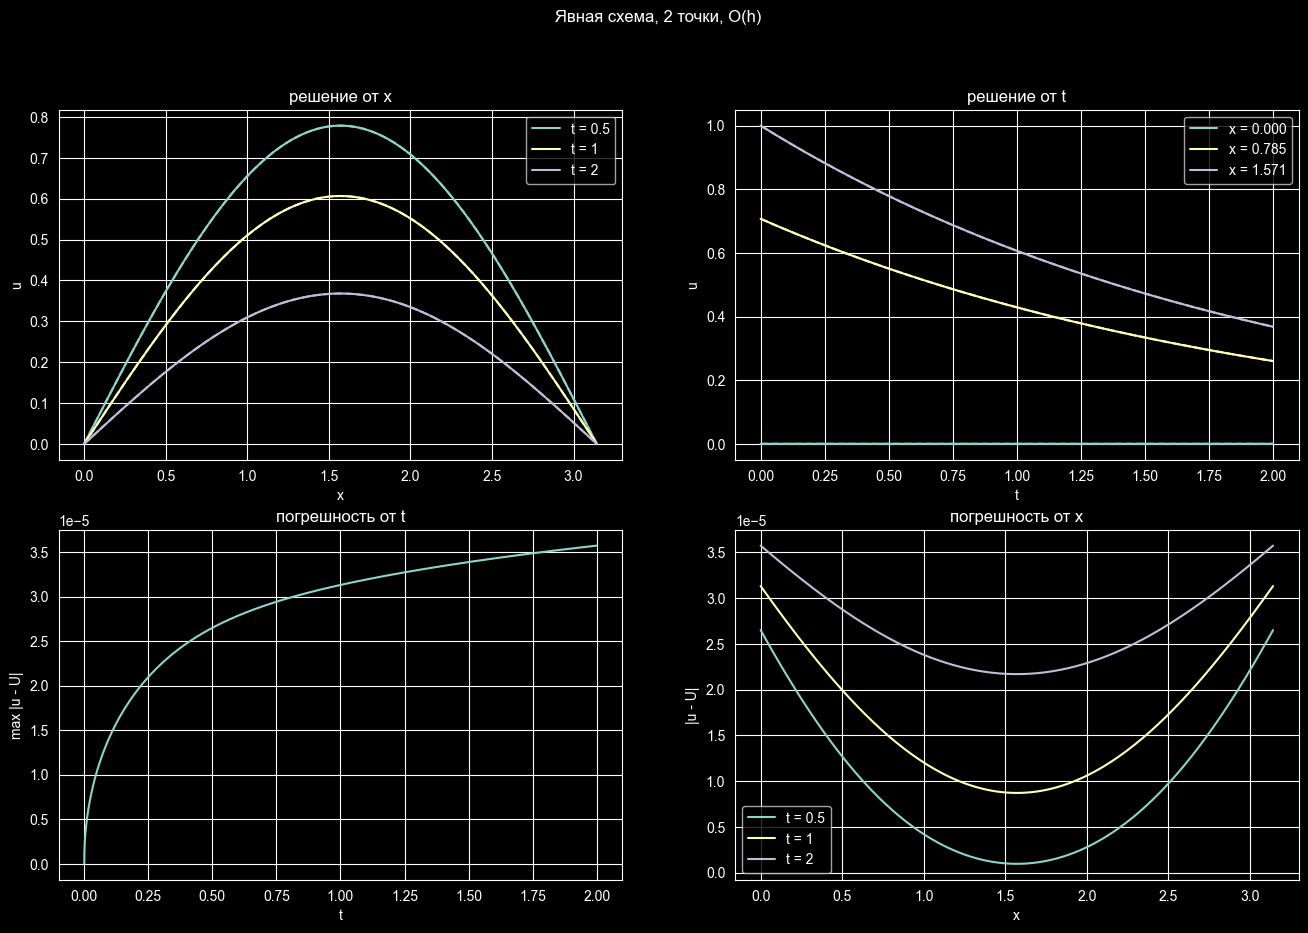

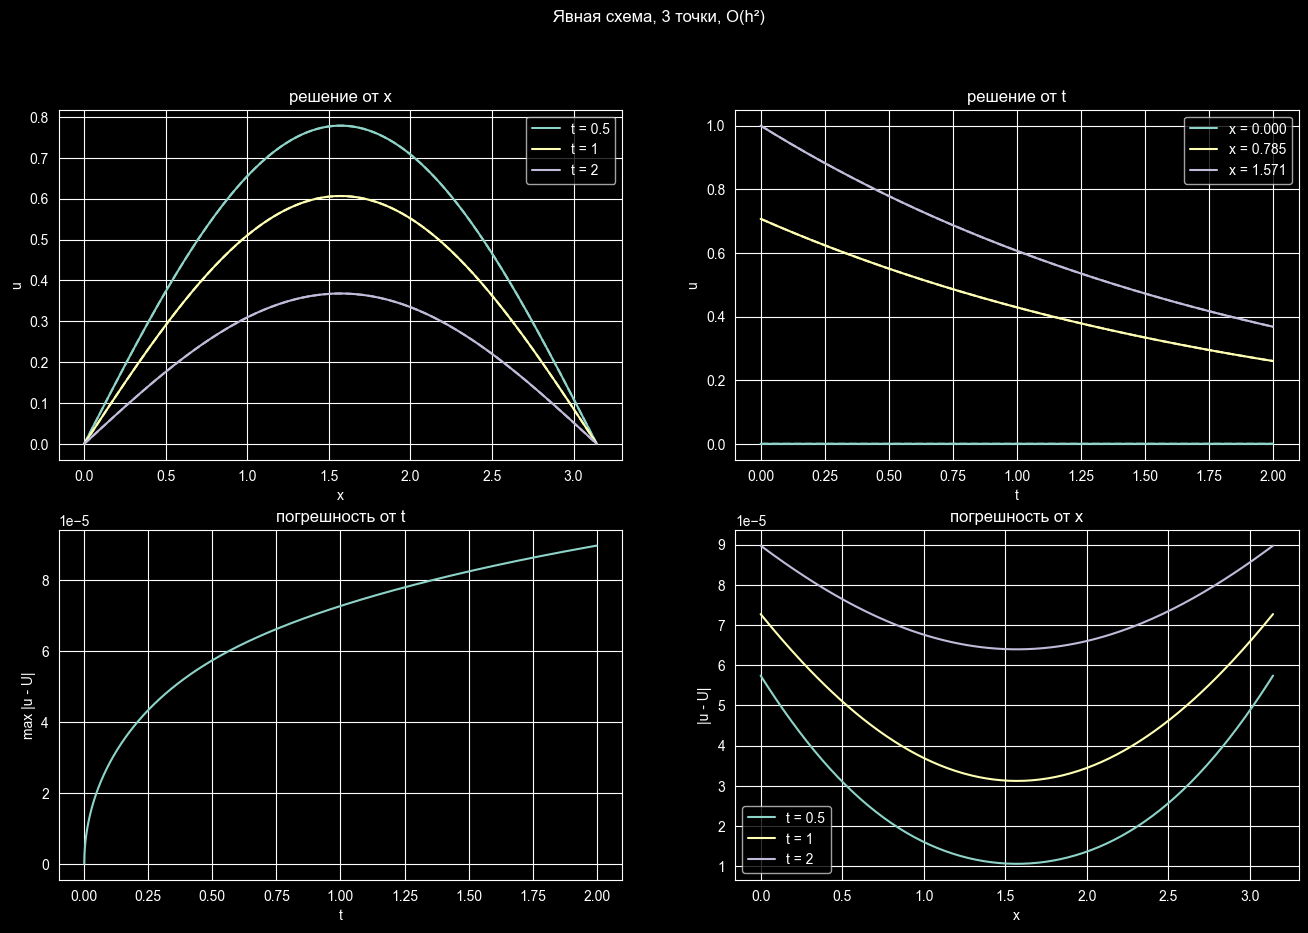

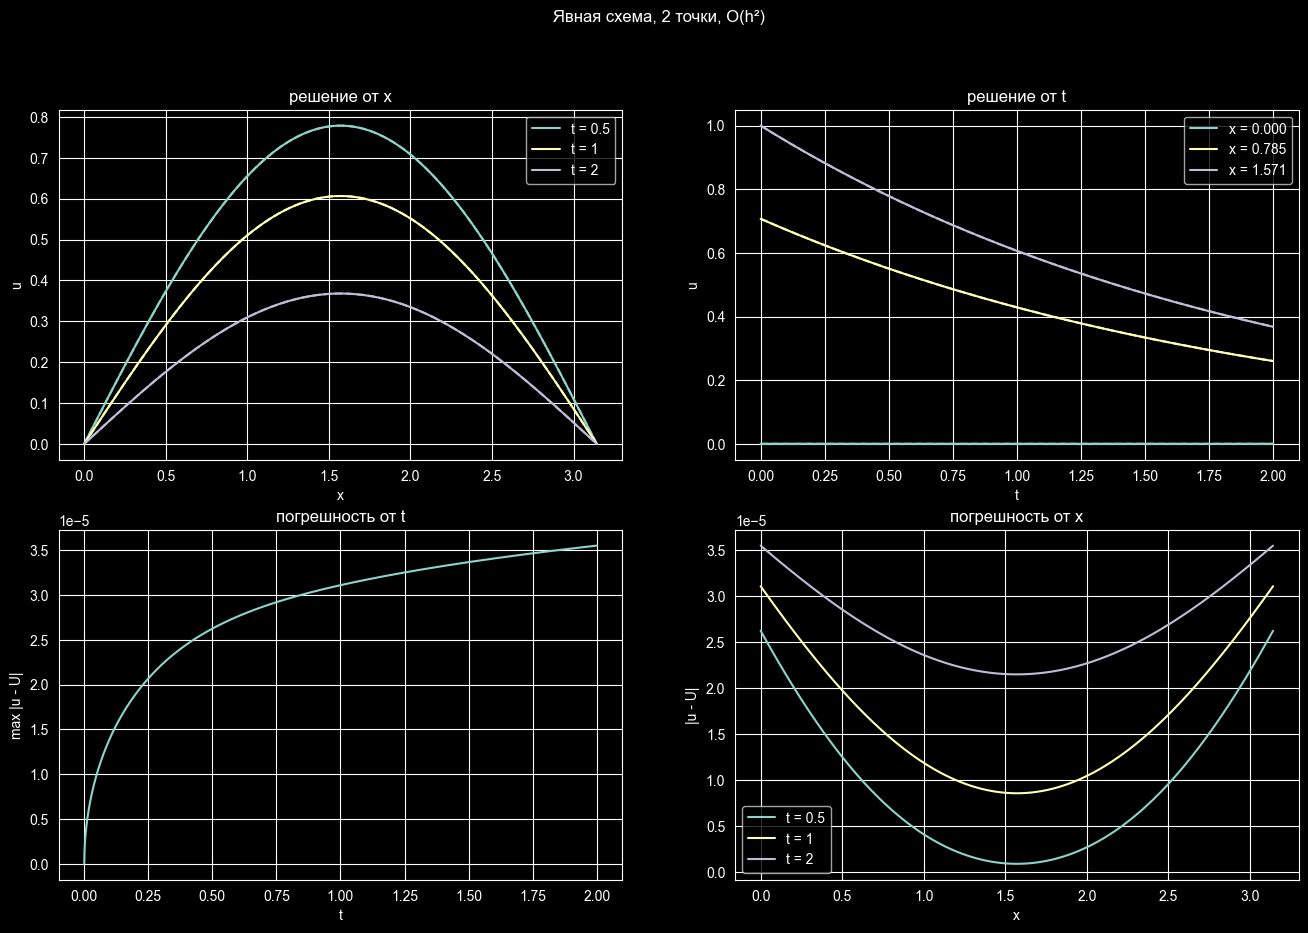

In [44]:
plot_results(explicit_results, 'Явная схема')

In [45]:
error_table(explicit_results)

,t = 0.25,t = 0.5,t = 1,t = 1.5,t = 2
"2 точки, O(h)",0.000021,0.000026,0.000031,0.000034,0.000036
"3 точки, O(h²)",0.000043,0.000057,0.000073,0.000082,0.000090
"2 точки, O(h²)",0.000021,0.000026,0.000031,0.000034,0.000036


### Зависимость погрешности от $h$

Уменьшаем $h$ вдвое при фиксированном $\sigma = 0.4$ (явная схема остаётся устойчивой, $\tau = \sigma h^2 / a^2$ уменьшается вчетверо). Для каждой сетки считаем погрешность $\varepsilon_h = \max_j |u_j - U(x_j, T)|$ и порядок $p = \log_2(\varepsilon_h / \varepsilon_{h/2})$.

In [46]:
def h_study(scheme, bcs, N_list, sigma):
    rows = []

    for bc_name, bc in bcs.items():
        errors = [error(*scheme(bc, n, steps_for_sigma(n, sigma)))[-1] for n in N_list]

        for i, n in enumerate(N_list):
            rows.append({
                'граничные условия': bc_name,
                'h': l / n,
                'погрешность': errors[i],
                'порядок': np.log2(errors[i - 1] / errors[i]) if i > 0 else np.nan,
            })

    return pd.DataFrame(rows)


def plot_convergence(study, step, title):
    ax = sns.lineplot(data=study, x=step, y='погрешность', hue='граничные условия', marker='o')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(title)


N_list = [10, 20, 40, 80, 160]

explicit_h_study = h_study(explicit_scheme, explicit_bcs, N_list, sigma)
explicit_h_study.pivot_table(index='граничные условия', columns='h', values=['погрешность', 'порядок'], sort=False)

погрешность                                          \
h                    0.314159  0.157080  0.078540  0.039270  0.019635   
граничные условия                                                       
2 точки, O(h)        0.015495  0.003729  0.000911  0.000225  0.000056   
3 точки, O(h²)       0.034574  0.008890  0.002238  0.000561  0.000140   
2 точки, O(h²)       0.013825  0.003528  0.000886  0.000222  0.000055   

                    порядок                                
h                  0.157080  0.078540  0.039270  0.019635  
граничные условия                                          
2 точки, O(h)      2.054857  2.033155  2.018045  2.009364  
3 точки, O(h²)     1.959364  1.989893  1.997480  1.999382  
2 точки, O(h²)     1.970467  1.992602  1.998148  1.999507

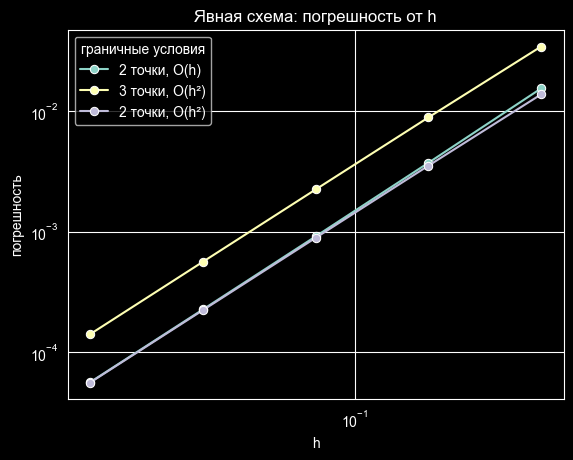

In [47]:
plot_convergence(explicit_h_study, 'h', 'Явная схема: погрешность от h')

### Устойчивость явной схемы

Проверим условие устойчивости $\sigma \le 1/2$: посчитаем погрешность при $t = T$ для нескольких $\sigma$. Берём более грубую сетку $N = 40$: при $N = 200$ неустойчивое решение за ~15 000 шагов переполняет тип `float64`, и погрешность получается бесконечной.

In [48]:
N_stability = 40
sigma_list = [0.25, 0.4, 0.5, 0.55, 0.6]

pd.DataFrame(
    {
        bc_name: [error(*explicit_scheme(bc, N_stability, steps_for_sigma(N_stability, s)))[-1] for s in sigma_list]
        for bc_name, bc in explicit_bcs.items()
    },
    index=pd.Index(sigma_list, name='σ'),
)

,"2 точки, O(h)","3 точки, O(h²)","2 точки, O(h²)"
σ,,,
0.25,8.212398e-04,2.326808e-03,7.995231e-04
0.40,9.111247e-04,2.238238e-03,8.864859e-04
0.50,9.710108e-04,2.179227e-03,9.444259e-04
0.55,2.529994e+38,2.477276e+38,1.401645e+38
0.60,5.193320e+70,5.118150e+70,3.056635e+70


При $\sigma > 1/2$ решение разрушается. Это ограничение $\tau \le h^2 / (2a^2)$ — главный недостаток явной схемы: при уменьшении $h$ вдвое шаг по времени приходится уменьшать вчетверо. Избавиться от него позволяет неявная схема.

# 2. Неявная конечно-разностная схема

## Внутренние узлы

Если вторую производную по $x$ аппроксимировать на **верхнем** временном слое

$
\left.\dfrac{\partial^2 u}{\partial x^2}\right|_j^{k+1} = \dfrac{u_{j+1}^{k+1} - 2u_j^{k+1} + u_{j-1}^{k+1}}{h^2} + O(h^2),
$

получаем неявную схему:

$
\dfrac{u_j^{k+1} - u_j^k}{\tau} = a^2\dfrac{u_{j+1}^{k+1} - 2u_j^{k+1} + u_{j-1}^{k+1}}{h^2} + f(x_j, t^{k+1}) + O(\tau + h^2), \qquad j = \overline{1, N-1}.
$

Теперь каждое уравнение содержит три неизвестных, и значения на верхнем слое находятся из СЛАУ с трёхдиагональной матрицей:

$
a_j u_{j-1}^{k+1} + b_j u_j^{k+1} + c_j u_{j+1}^{k+1} = d_j,
$

$
a_j = \sigma, \quad b_j = -(1 + 2\sigma), \quad c_j = \sigma, \quad d_j = -u_j^k - \tau f(x_j, t^{k+1}), \qquad \sigma = \dfrac{a^2\tau}{h^2}.
$

Неявная схема абсолютно устойчива, то есть $\tau$ и $h$ можно выбирать независимо.

## Метод прогонки

СЛАУ $a_j u_{j-1} + b_j u_j + c_j u_{j+1} = d_j$, $j = \overline{0, N}$ ($a_0 = 0$, $c_N = 0$) решаем методом прогонки, реализованным в ЛР 1.2. Прогоночные коэффициенты там нумеруются со сдвигом на единицу:

$
P_{j+1} = -\dfrac{c_j}{b_j + a_j P_j}, \qquad Q_{j+1} = \dfrac{d_j - a_j Q_j}{b_j + a_j P_j}, \qquad P_0 = Q_0 = 0,
$

обратный ход (5.32):

$
u_N = Q_{N+1}, \qquad u_j = P_{j+1} u_{j+1} + Q_{j+1}, \quad j = N-1, \dots, 0.
$

Коэффициенты системы, как в ЛР 1.2, хранятся построчно в матрице размера $(N + 1) \times 3$ со столбцами $a_j$, $b_j$, $c_j$.

In [49]:
def tridiagonal_solve(slau, d):
    n = len(d)
    P, Q = np.zeros(n + 1, dtype=float), np.zeros(n + 1, dtype=float)

    P[0], Q[0] = 0, 0

    for i in range(0, n):
        P[i + 1] = -slau[i, 2] / (slau[i, 1] + slau[i, 0] * P[i])
        Q[i + 1] = (d[i] - slau[i, 0] * Q[i]) / (slau[i, 1] + slau[i, 0] * P[i])

    x = np.zeros(n, dtype=float)

    for i in range(n, 0, -1):
        if P[i] == 0:
            x[i - 1] = Q[i]
            continue
        x[i - 1] = P[i] * x[i] + Q[i]

    return x

## Граничные узлы

В неявной схеме граничные значения нельзя найти после внутренних — аппроксимации граничных условий становятся **первой и последней строками СЛАУ**. Формулы аппроксимации те же, что и для явной схемы, меняется только способ их использования. Функции ниже дописывают строки $j = 0$ и $j = N$ в уже заполненную для внутренних узлов систему `A`, `d`.

### Двухточечная аппроксимация с первым порядком

Из тех же уравнений, что и в явной схеме, получаем:

$
b_0 = \beta - \dfrac{\alpha}{h}, \quad c_0 = \dfrac{\alpha}{h}, \quad d_0 = \varphi_0(t^{k+1}); \qquad
a_N = -\dfrac{\gamma}{h}, \quad b_N = \delta + \dfrac{\gamma}{h}, \quad d_N = \varphi_l(t^{k+1}).
$

In [50]:
def implicit_boundary_two_point_first_order(A, d, time_step):
    t_next, h = time_step.t_next, time_step.h

    A[0, 1], A[0, 2], d[0] = beta - alpha / h, alpha / h, phi_0(t_next)
    A[-1, 0], A[-1, 1], d[-1] = -gamma / h, delta + gamma / h, phi_l(t_next)

### Трёхточечная аппроксимация со вторым порядком

Здесь первое и последнее уравнения содержат по три неизвестных:

$
\left(\beta - \dfrac{3\alpha}{2h}\right)u_0^{k+1} + \dfrac{2\alpha}{h}u_1^{k+1} - \dfrac{\alpha}{2h}u_2^{k+1} = \varphi_0(t^{k+1}), \qquad
\dfrac{\gamma}{2h}u_{N-2}^{k+1} - \dfrac{2\gamma}{h}u_{N-1}^{k+1} + \left(\delta + \dfrac{3\gamma}{2h}\right)u_N^{k+1} = \varphi_l(t^{k+1}),
$

и матрица перестаёт быть трёхдиагональной. Как предложено в методичке, исключим лишнее неизвестное линейной комбинацией с соседним уравнением. Обозначим коэффициенты при $u_0, u_1, u_2$ в первом уравнении через $b_0, c_0, e_0$. Вычтем из него уравнение $j = 1$ ($a_1u_0 + b_1u_1 + c_1u_2 = d_1$), умноженное на $q_0 = e_0 / c_1$:

$
(b_0 - q_0 a_1)\,u_0^{k+1} + (c_0 - q_0 b_1)\,u_1^{k+1} = d_0 - q_0 d_1.
$

Аналогично для последнего уравнения (коэффициенты $e_N, a_N, b_N$ при $u_{N-2}, u_{N-1}, u_N$) и уравнения $j = N-1$ с $q_N = e_N / a_{N-1}$:

$
(a_N - q_N b_{N-1})\,u_{N-1}^{k+1} + (b_N - q_N c_{N-1})\,u_N^{k+1} = d_N - q_N d_{N-1}.
$

In [51]:
def implicit_boundary_three_point_second_order(A, d, time_step):
    t_next, h = time_step.t_next, time_step.h

    b_0, c_0, e_0, d_0 = beta - 3 * alpha / (2 * h), 2 * alpha / h, -alpha / (2 * h), phi_0(t_next)
    e_N, a_N, b_N, d_N = gamma / (2 * h), -2 * gamma / h, delta + 3 * gamma / (2 * h), phi_l(t_next)

    # исключаем u_2 с помощью уравнения j = 1
    q_0 = e_0 / A[1, 2]
    A[0, 1], A[0, 2], d[0] = b_0 - q_0 * A[1, 0], c_0 - q_0 * A[1, 1], d_0 - q_0 * d[1]

    # исключаем u_{N-2} с помощью уравнения j = N - 1
    q_N = e_N / A[-2, 0]
    A[-1, 0], A[-1, 1], d[-1] = a_N - q_N * A[-2, 1], b_N - q_N * A[-2, 2], d_N - q_N * d[-2]

### Двухточечная аппроксимация со вторым порядком

Уравнения, выведенные для явной схемы, уже содержат по два неизвестных, поэтому сразу ставятся в СЛАУ без изменений — именно для неявной схемы этот способ и предложен в методичке:

$
b_0 = \dfrac{2a^2}{h} + \dfrac{h}{\tau} - gh - \dfrac{\beta}{\alpha}(2a^2 - bh), \quad c_0 = -\dfrac{2a^2}{h}, \quad
d_0 = \dfrac{h}{\tau}u_0^k - \varphi_0(t^{k+1})\dfrac{2a^2 - bh}{\alpha} + h f_0^{k+1};
$

$
a_N = -\dfrac{2a^2}{h}, \quad b_N = \dfrac{2a^2}{h} + \dfrac{h}{\tau} - gh + \dfrac{\delta}{\gamma}(2a^2 + bh), \quad
d_N = \dfrac{h}{\tau}u_N^k + \varphi_l(t^{k+1})\dfrac{2a^2 + bh}{\gamma} + h f_N^{k+1}.
$

In [52]:
def implicit_boundary_two_point_second_order(A, d, time_step):
    t_next, h, tau, u_prev = time_step

    A[0, 1] = 2 * a * a / h + h / tau - g * h - beta / alpha * (2 * a * a - b * h)
    A[0, 2] = -2 * a * a / h
    d[0] = h / tau * u_prev[0] - phi_0(t_next) * (2 * a * a - b * h) / alpha + h * f(0, t_next)

    A[-1, 0] = -2 * a * a / h
    A[-1, 1] = 2 * a * a / h + h / tau - g * h + delta / gamma * (2 * a * a + b * h)
    d[-1] = h / tau * u_prev[-1] + phi_l(t_next) * (2 * a * a + b * h) / gamma + h * f(l, t_next)

## Алгоритм неявной схемы

На каждом шаге по времени заполняем строки СЛАУ для внутренних узлов, дописываем граничные строки и решаем систему прогонкой.

In [53]:
def implicit_scheme(bc, N, K):
    x, t, h, tau = make_grid(N, K)
    sigma = a * a * tau / (h * h)

    u = np.zeros((K + 1, N + 1), dtype=np.float64)
    u[0] = psi(x)

    for k in range(K):
        A = np.zeros((N + 1, 3), dtype=np.float64)
        d = np.zeros(N + 1, dtype=np.float64)

        A[1:-1, 0] = sigma
        A[1:-1, 1] = -(1 + 2 * sigma)
        A[1:-1, 2] = sigma
        d[1:-1] = -u[k, 1:-1] - tau * f(x[1:-1], t[k + 1])

        bc(A, d, TimeStep(t[k + 1], h, tau, u[k]))

        u[k + 1] = tridiagonal_solve(A, d)

    return x, t, u

## Результаты неявной схемы

На той же сетке, что и для явной схемы:

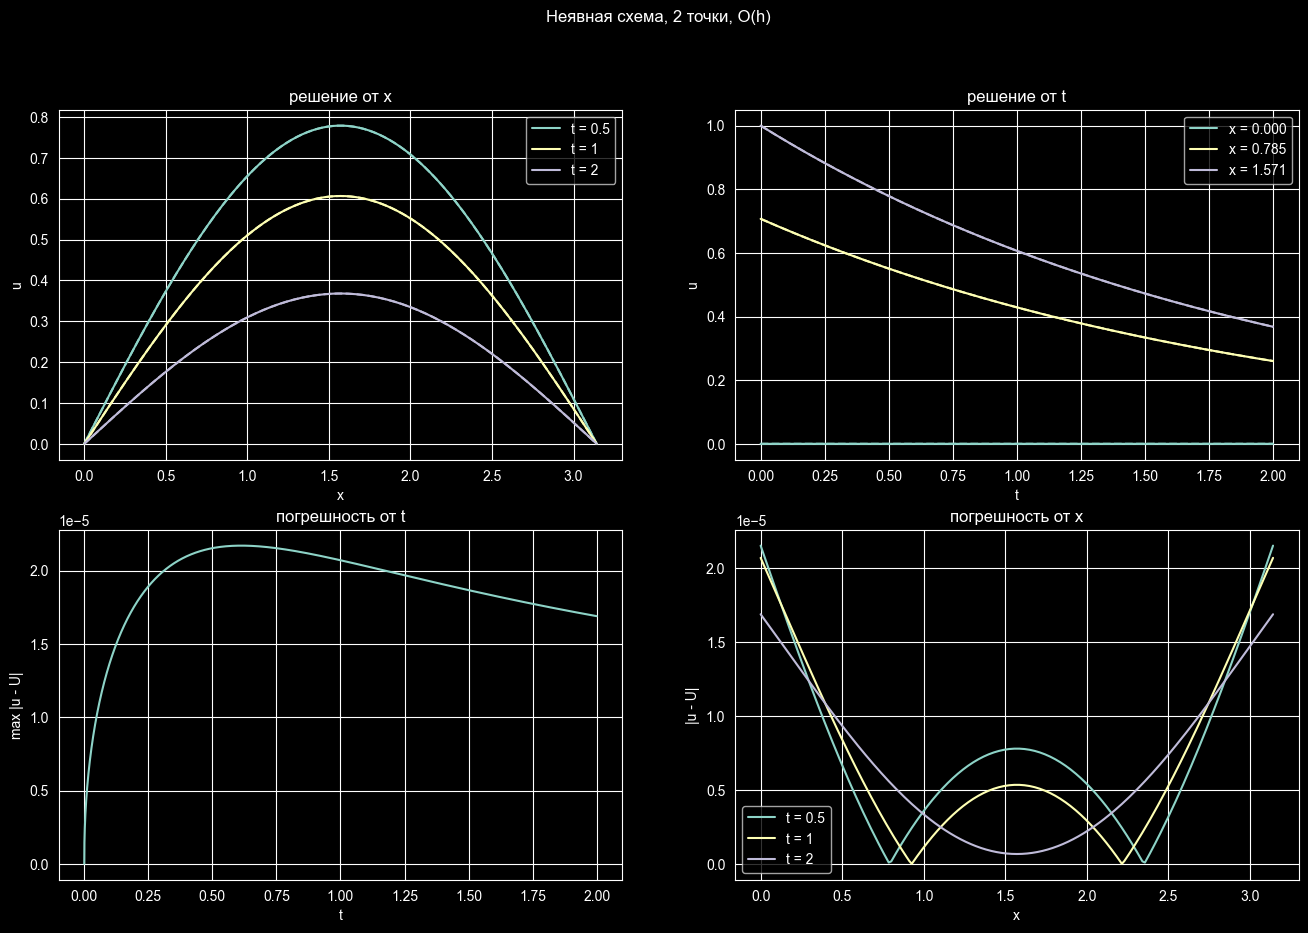

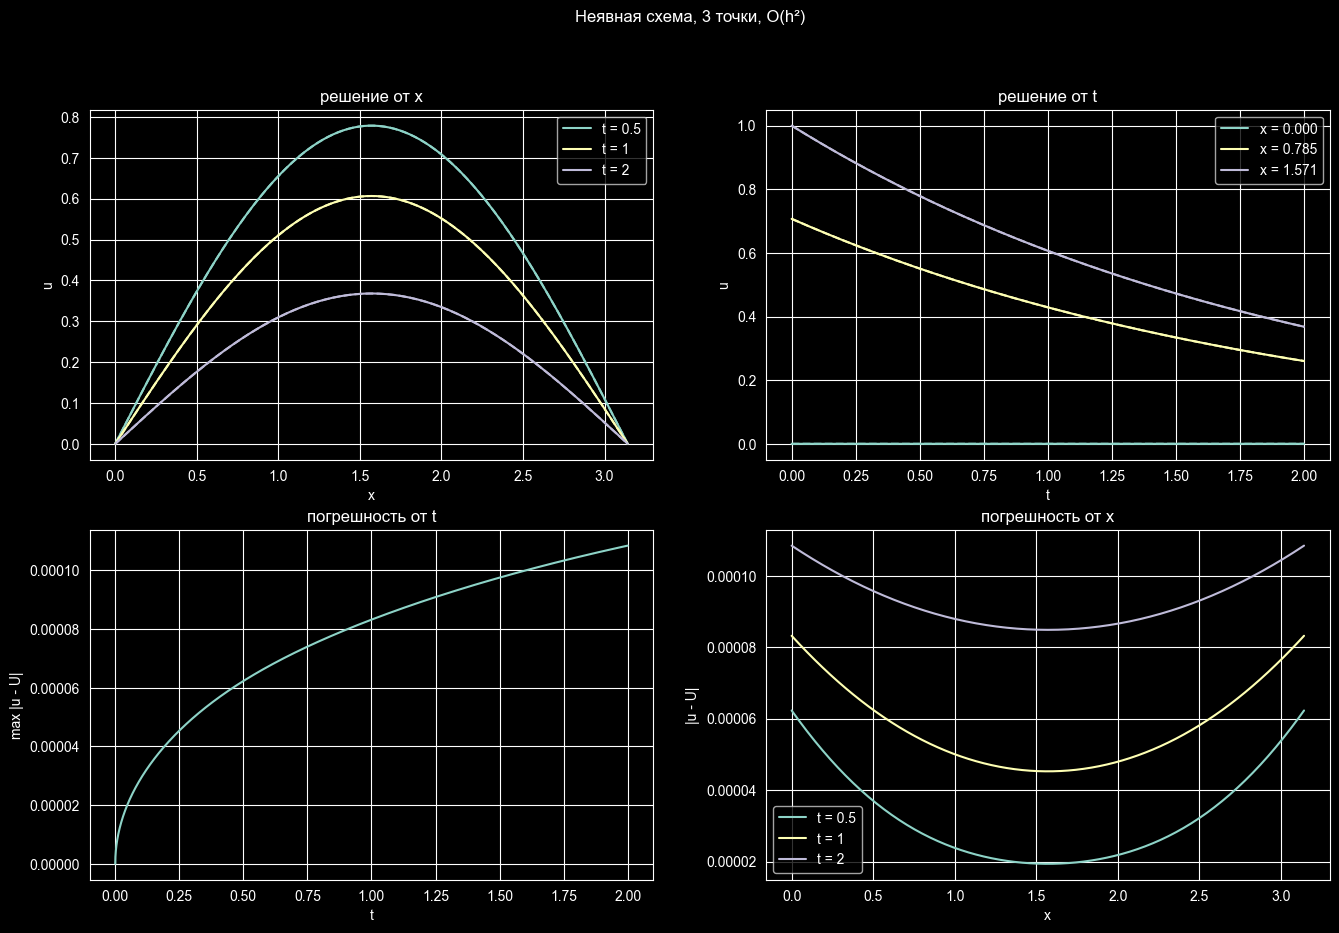

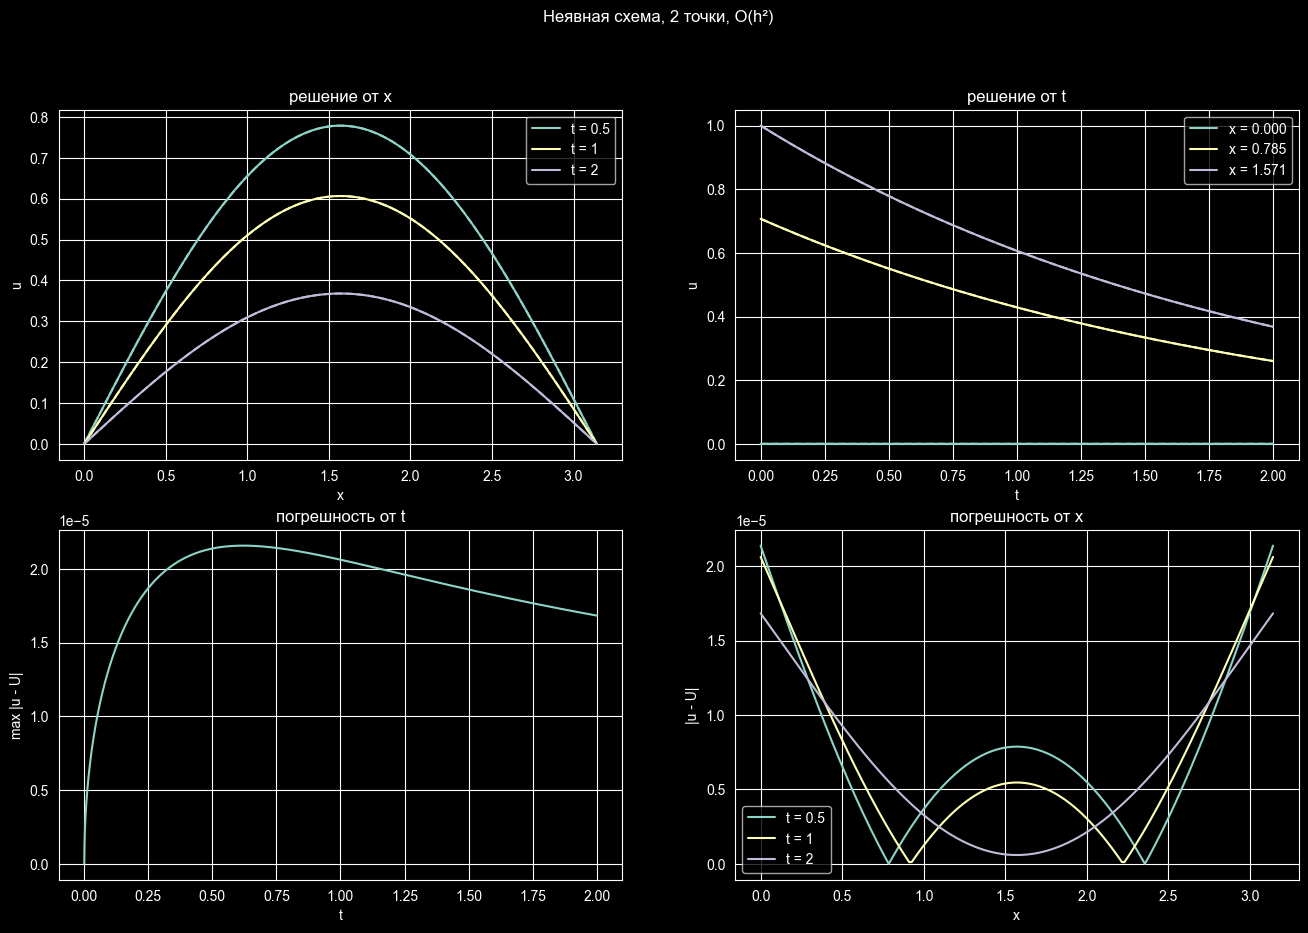

In [54]:
implicit_bcs = {
    '2 точки, O(h)': implicit_boundary_two_point_first_order,
    '3 точки, O(h²)': implicit_boundary_three_point_second_order,
    '2 точки, O(h²)': implicit_boundary_two_point_second_order,
}

implicit_results = {bc_name: implicit_scheme(bc, N, K) for bc_name, bc in implicit_bcs.items()}

plot_results(implicit_results, 'Неявная схема')

In [55]:
error_table(implicit_results)

,t = 0.25,t = 0.5,t = 1,t = 1.5,t = 2
"2 точки, O(h)",0.000019,0.000022,0.000021,0.000019,0.000017
"3 точки, O(h²)",0.000045,0.000062,0.000083,0.000098,0.000108
"2 точки, O(h²)",0.000019,0.000021,0.000021,0.000019,0.000017


### Зависимость погрешности от $h$

Для сравнения с явной схемой берём те же сетки ($\sigma = 0.4$):

In [56]:
implicit_h_study = h_study(implicit_scheme, implicit_bcs, N_list, sigma)
implicit_h_study.pivot_table(index='граничные условия', columns='h', values=['погрешность', 'порядок'], sort=False)

погрешность                                          \
h                    0.314159  0.157080  0.078540  0.039270  0.019635   
граничные условия                                                       
2 точки, O(h)        0.007405  0.001760  0.000430  0.000106  0.000026   
3 точки, O(h²)       0.042540  0.010792  0.002708  0.000677  0.000169   
2 точки, O(h²)       0.006783  0.001686  0.000421  0.000105  0.000026   

                    порядок                                
h                  0.157080  0.078540  0.039270  0.019635  
граничные условия                                          
2 точки, O(h)      2.073162  2.033321  2.015868  2.007802  
3 точки, O(h²)     1.978899  1.994843  1.998723  1.999672  
2 точки, O(h²)     2.008340  2.002108  2.000528  2.000194

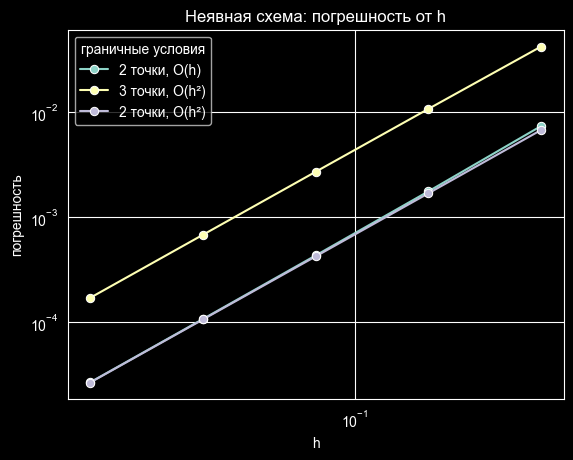

In [57]:
plot_convergence(implicit_h_study, 'h', 'Неявная схема: погрешность от h')

### Зависимость погрешности от $\tau$

Неявная схема абсолютно устойчива, поэтому $\tau$ не обязан уменьшаться как $h^2$. Но если уменьшать только $\tau$ при фиксированном $h$, погрешность $\varepsilon \approx C_1\tau + C_2h^2$ упрётся в пространственную составляющую $C_2h^2$.

Поэтому уменьшаем $\tau$ и $h$ вдвое одновременно, сохраняя $\tau / h = \text{const}$ (берём $K = N$, то есть $\tau / h = T / l$). Тогда при малых шагах главным становится член по $\tau$, и порядок по времени $p = \log_2(\varepsilon_\tau / \varepsilon_{\tau/2})$.

In [58]:
def tau_study(scheme, bcs, N_list):
    rows = []

    for bc_name, bc in bcs.items():
        errors = [error(*scheme(bc, n, n))[-1] for n in N_list]

        for i, n in enumerate(N_list):
            rows.append({
                'граничные условия': bc_name,
                'tau': T / n,
                'h': l / n,
                'погрешность': errors[i],
                'порядок': np.log2(errors[i - 1] / errors[i]) if i > 0 else np.nan,
            })

    return pd.DataFrame(rows)


implicit_tau_study = tau_study(implicit_scheme, implicit_bcs, N_list)
implicit_tau_study.pivot_table(index='граничные условия', columns='tau', values=['погрешность', 'порядок'], sort=False)

погрешность                                          \
tau                    0.2000    0.1000    0.0500    0.0250    0.0125   
граничные условия                                                       
2 точки, O(h)        0.017381  0.009732  0.005092  0.002599  0.001312   
3 точки, O(h²)       0.056887  0.019162  0.007176  0.003108  0.001439   
2 точки, O(h²)       0.016743  0.009448  0.005007  0.002576  0.001306   

                    порядок                                
tau                  0.1000    0.0500    0.0250    0.0125  
граничные условия                                          
2 точки, O(h)      0.836751  0.934382  0.970457  0.985974  
3 точки, O(h²)     1.569834  1.416998  1.207399  1.110339  
2 точки, O(h²)     0.825450  0.916075  0.958931  0.979694

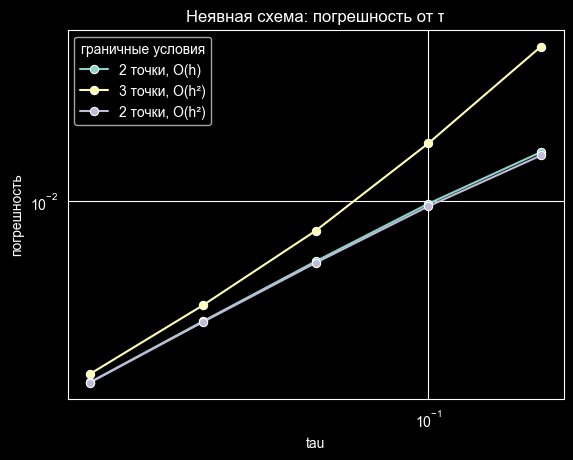

In [59]:
plot_convergence(implicit_tau_study, 'tau', 'Неявная схема: погрешность от τ')

Неявная схема устойчива при любом $\tau$, но имеет лишь первый порядок по времени. Явная схема на возрастающем решении занижает, а неявная завышает результат (и наоборот на убывающем), поэтому естественно взять их взвешенную комбинацию.

# 3. Схема Кранка–Николсона

## Неявно-явная схема с весами

Возьмём вторую производную по $x$ с весом $\theta$ на верхнем слое и $1 - \theta$ на нижнем, источник — с теми же весами:

$
\dfrac{u_j^{k+1} - u_j^k}{\tau} = \theta a^2 \dfrac{u_{j+1}^{k+1} - 2u_j^{k+1} + u_{j-1}^{k+1}}{h^2} + (1 - \theta) a^2 \dfrac{u_{j+1}^k - 2u_j^k + u_{j-1}^k}{h^2} + \theta f_j^{k+1} + (1 - \theta) f_j^k.
$

При $\theta = 0$ это явная схема, при $\theta = 1$ — неявная, при $\theta = 1/2$ — схема Кранка–Николсона с порядком $O(\tau^2 + h^2)$. При $1/2 \le \theta \le 1$ схема абсолютно устойчива.

Переносим неизвестные влево и получаем трёхдиагональную систему того же вида, что и для неявной схемы:

$
a_j = \theta\sigma, \quad b_j = -(1 + 2\theta\sigma), \quad c_j = \theta\sigma,
$

$
d_j = -\left(u_j^k + (1 - \theta)\sigma\,(u_{j+1}^k - 2u_j^k + u_{j-1}^k) + \tau\left(\theta f_j^{k+1} + (1 - \theta) f_j^k\right)\right).
$

Граничные строки СЛАУ берём те же, что и для неявной схемы (в трёхточечной аппроксимации исключение лишнего неизвестного автоматически использует новые коэффициенты строк $j = 1$ и $j = N-1$).

In [60]:
def weighted_scheme(theta, bc, N, K):
    x, t, h, tau = make_grid(N, K)
    sigma = a * a * tau / (h * h)

    u = np.zeros((K + 1, N + 1), dtype=np.float64)
    u[0] = psi(x)

    for k in range(K):
        A = np.zeros((N + 1, 3), dtype=np.float64)
        d = np.zeros(N + 1, dtype=np.float64)

        A[1:-1, 0] = theta * sigma
        A[1:-1, 1] = -(1 + 2 * theta * sigma)
        A[1:-1, 2] = theta * sigma
        d[1:-1] = -(
            u[k, 1:-1]
            + (1 - theta) * sigma * (u[k, 2:] - 2 * u[k, 1:-1] + u[k, :-2])
            + tau * (theta * f(x[1:-1], t[k + 1]) + (1 - theta) * f(x[1:-1], t[k]))
        )

        bc(A, d, TimeStep(t[k + 1], h, tau, u[k]))

        u[k + 1] = tridiagonal_solve(A, d)

    return x, t, u


crank_nicolson_scheme = lambda bc, N, K: weighted_scheme(0.5, bc, N, K)

Проверим, что при $\theta = 1$ схема с весами совпадает с реализованной ранее неявной схемой:

In [61]:
all(
    np.allclose(weighted_scheme(1, bc, N, K)[2], implicit_results[bc_name][2])
    for bc_name, bc in implicit_bcs.items()
)

True

## Результаты схемы Кранка–Николсона

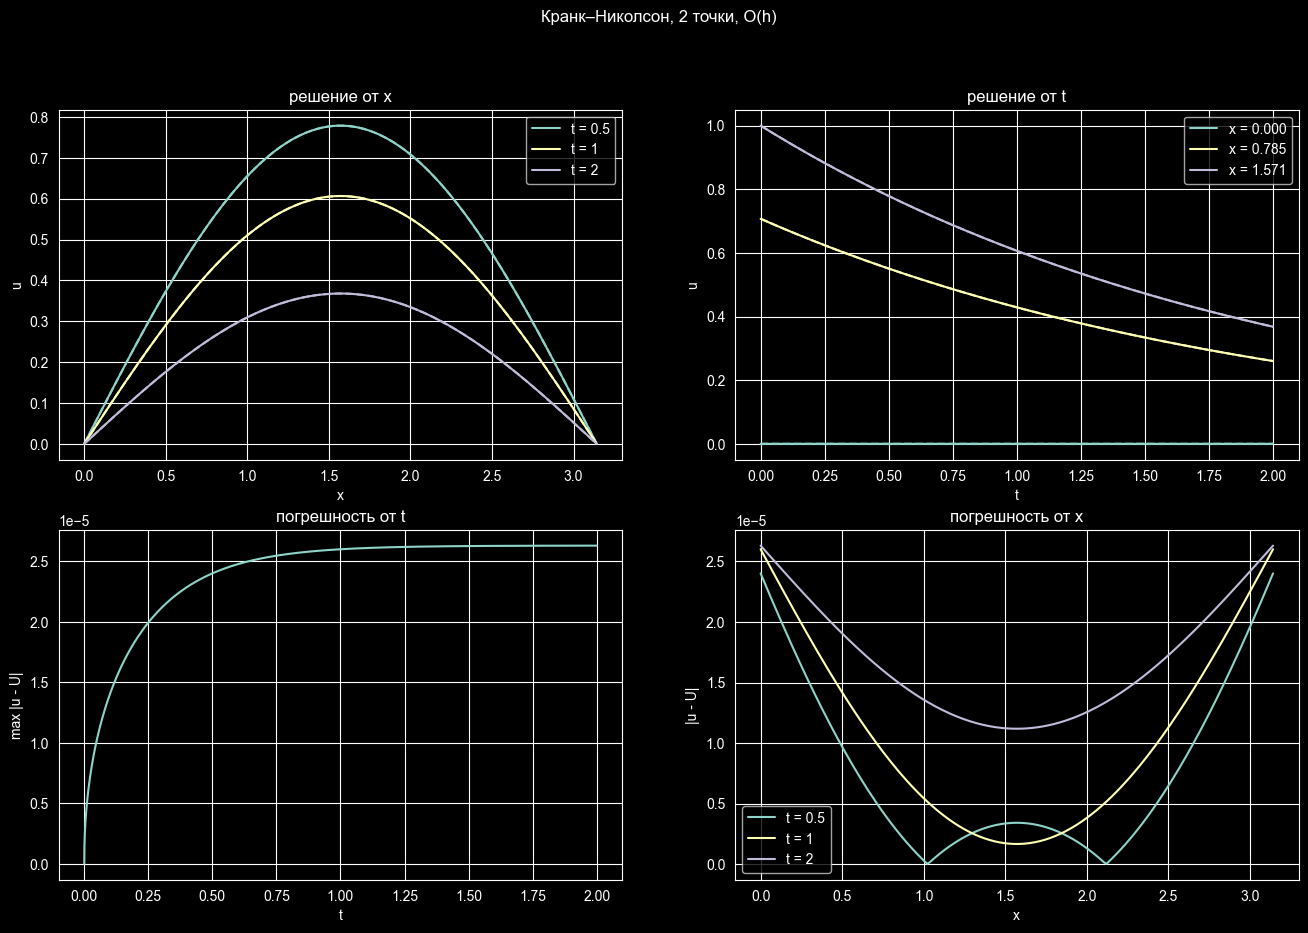

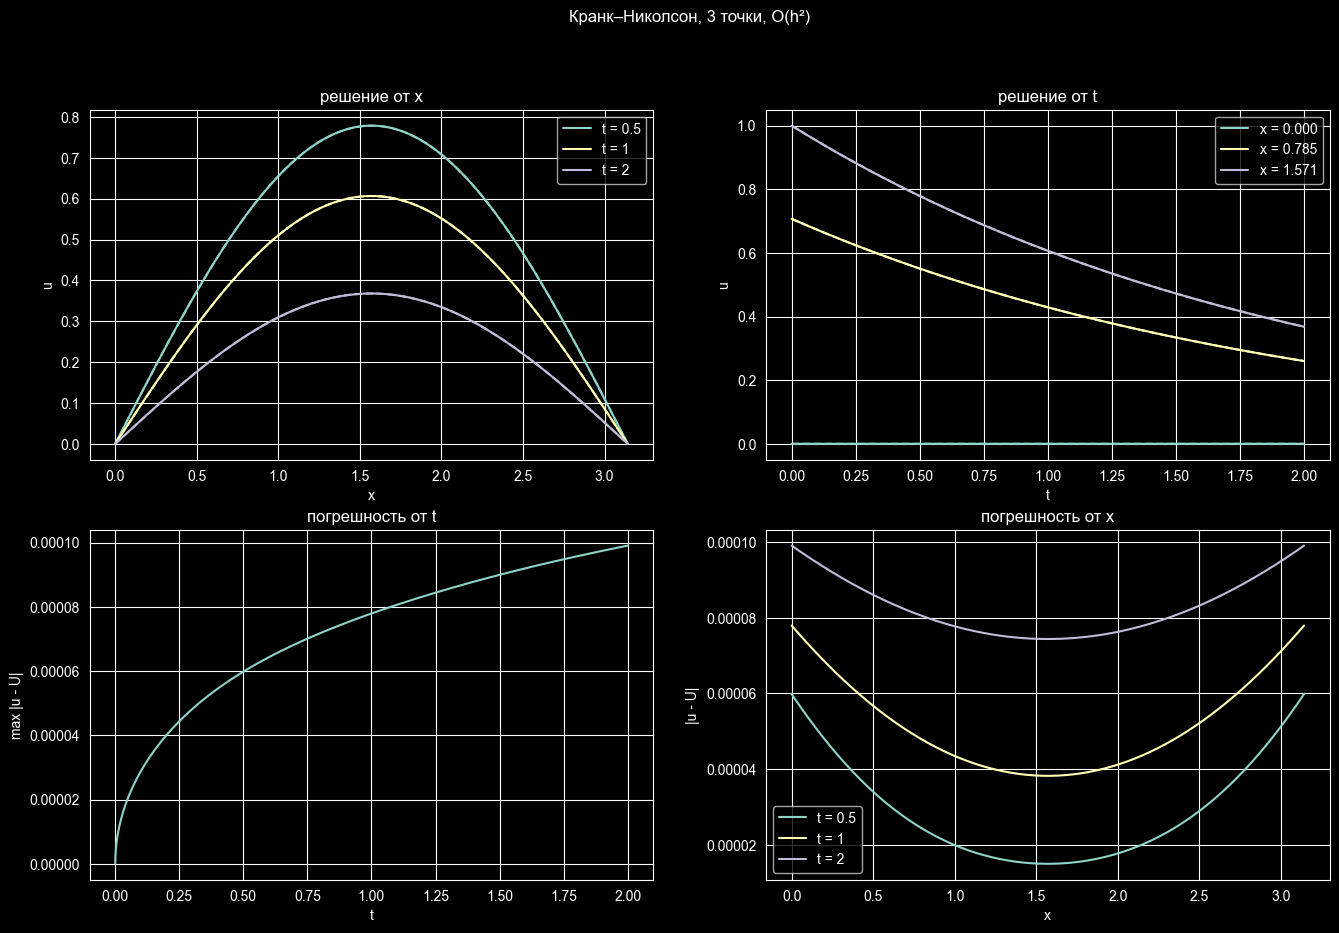

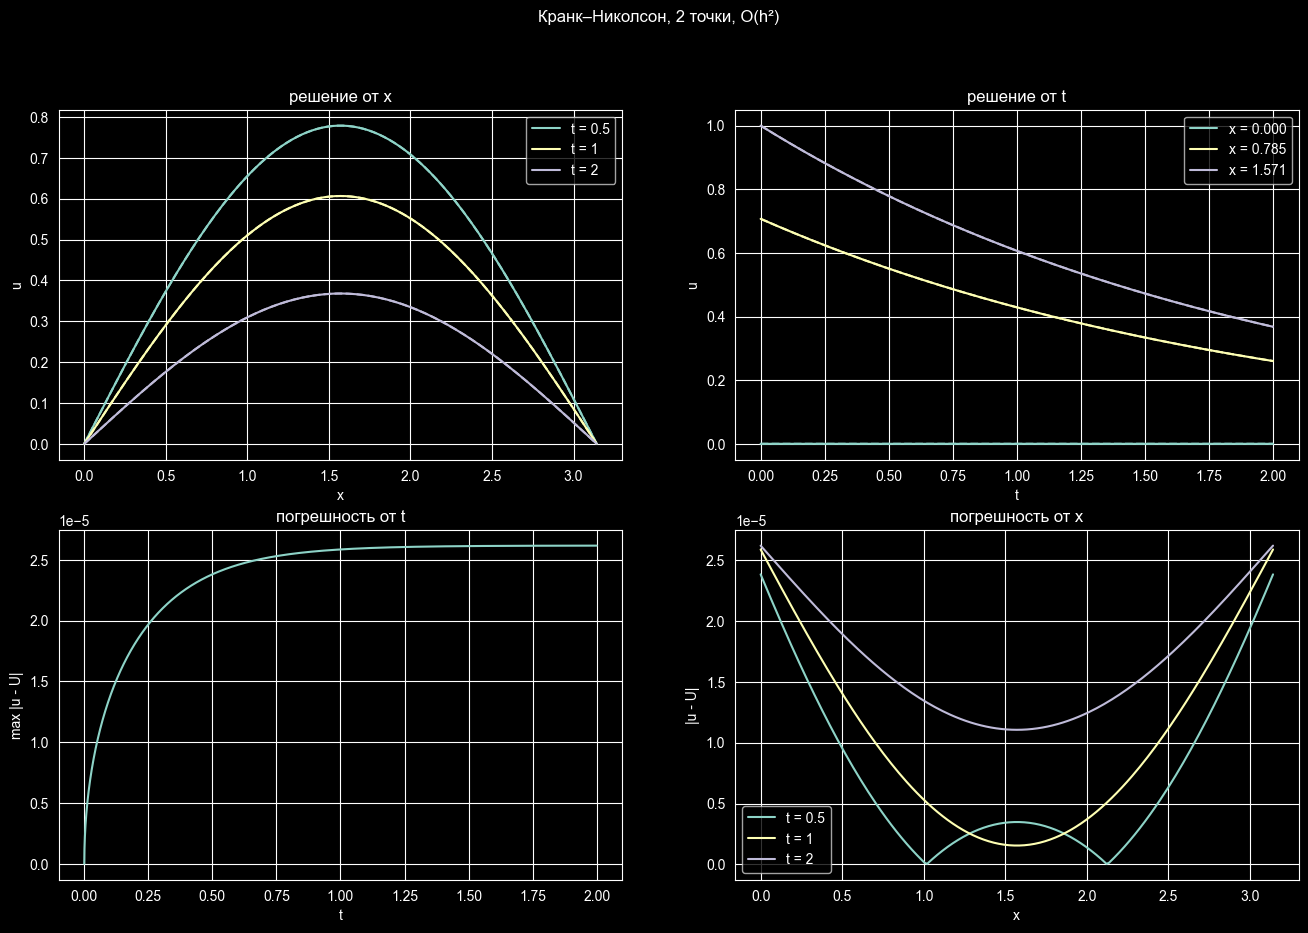

In [62]:
cn_results = {bc_name: crank_nicolson_scheme(bc, N, K) for bc_name, bc in implicit_bcs.items()}

plot_results(cn_results, 'Кранк–Николсон')

In [63]:
error_table(cn_results)

,t = 0.25,t = 0.5,t = 1,t = 1.5,t = 2
"2 точки, O(h)",0.000020,0.000024,0.000026,0.000026,0.000026
"3 точки, O(h²)",0.000044,0.000060,0.000078,0.000090,0.000099
"2 точки, O(h²)",0.000020,0.000024,0.000026,0.000026,0.000026


### Зависимость погрешности от $h$

In [64]:
cn_h_study = h_study(crank_nicolson_scheme, implicit_bcs, N_list, sigma)
cn_h_study.pivot_table(index='граничные условия', columns='h', values=['погрешность', 'порядок'], sort=False)

погрешность                                          \
h                    0.314159  0.157080  0.078540  0.039270  0.019635   
граничные условия                                                       
2 точки, O(h)        0.011449  0.002744  0.000671  0.000166  0.000041   
3 точки, O(h²)       0.038559  0.009841  0.002473  0.000619  0.000155   
2 точки, O(h²)       0.010300  0.002607  0.000654  0.000164  0.000041   

                    порядок                                
h                  0.157080  0.078540  0.039270  0.019635  
граничные условия                                          
2 точки, O(h)      2.060630  2.033162  2.017333  2.008859  
3 точки, O(h²)     1.970176  1.992622  1.998165  1.999542  
2 точки, O(h²)     1.982386  1.995583  1.998895  1.999724

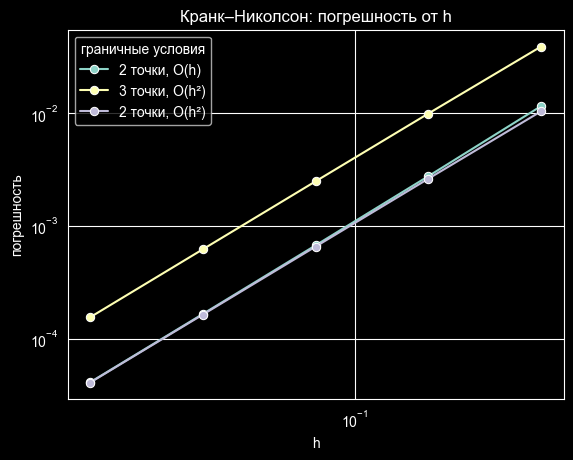

In [65]:
plot_convergence(cn_h_study, 'h', 'Кранк–Николсон: погрешность от h')

### Зависимость погрешности от $\tau$

На тех же сетках, что и для неявной схемы:

In [66]:
cn_tau_study = tau_study(crank_nicolson_scheme, implicit_bcs, N_list)
cn_tau_study.pivot_table(index='граничные условия', columns='tau', values=['погрешность', 'порядок'], sort=False)

погрешность                                          \
tau                    0.2000    0.1000    0.0500    0.0250    0.0125   
граничные условия                                                       
2 точки, O(h)        0.010867  0.002704  0.000675  0.000169  0.000042   
3 точки, O(h²)       0.036640  0.009530  0.002422  0.000610  0.000153   
2 точки, O(h²)       0.009765  0.002567  0.000658  0.000166  0.000042   

                    порядок                                
tau                  0.1000    0.0500    0.0250    0.0125  
граничные условия                                          
2 точки, O(h)      2.006851  2.002318  2.000936  2.000419  
3 точки, O(h²)     1.942936  1.976099  1.989212  1.994899  
2 точки, O(h²)     1.927551  1.964333  1.982317  1.991198

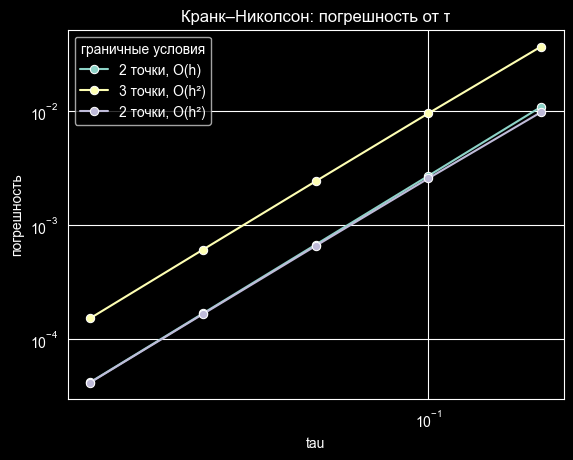

In [67]:
plot_convergence(cn_tau_study, 'tau', 'Кранк–Николсон: погрешность от τ')

# 4. Сравнение схем

Погрешность относительно $U$ в различные моменты времени для всех схем на одной сетке ($N = 200$, $\sigma = 0.4$):

In [68]:
pd.concat(
    {
        'Явная': error_table(explicit_results),
        'Неявная': error_table(implicit_results),
        'Кранк–Николсон': error_table(cn_results),
    },
    names=['схема', 'граничные условия'],
)

t = 0.25   t = 0.5     t = 1   t = 1.5  \
схема          граничные условия                                           
Явная          2 точки, O(h)      0.000021  0.000026  0.000031  0.000034   
               3 точки, O(h²)     0.000043  0.000057  0.000073  0.000082   
               2 точки, O(h²)     0.000021  0.000026  0.000031  0.000034   
Неявная        2 точки, O(h)      0.000019  0.000022  0.000021  0.000019   
               3 точки, O(h²)     0.000045  0.000062  0.000083  0.000098   
               2 точки, O(h²)     0.000019  0.000021  0.000021  0.000019   
Кранк–Николсон 2 точки, O(h)      0.000020  0.000024  0.000026  0.000026   
               3 точки, O(h²)     0.000044  0.000060  0.000078  0.000090   
               2 точки, O(h²)     0.000020  0.000024  0.000026  0.000026   

                                     t = 2  
схема          граничные условия            
Явная          2 точки, O(h)      0.000036  
               3 точки, O(h²)     0.000090  
               2 точки, O(h²)     0.000036  
Неявная        2 точки, O(h)      0.000017  
               3 точки, O(h²)     0.000108  
               2 точки, O(h²)     0.000017  
Кранк–Николсон 2 точки, O(h)      0.000026  
               3 точки, O(h²)     0.000099  
               2 точки, O(h²)     0.000026

Наблюдаемые порядки на самых мелких сетках:

In [69]:
def last_order(study):
    return study.groupby('граничные условия', sort=False)['порядок'].last()


pd.DataFrame({
    ('по h', 'Явная'): last_order(explicit_h_study),
    ('по h', 'Неявная'): last_order(implicit_h_study),
    ('по h', 'Кранк–Николсон'): last_order(cn_h_study),
    ('по τ', 'Неявная'): last_order(implicit_tau_study),
    ('по τ', 'Кранк–Николсон'): last_order(cn_tau_study),
})

по h                               по τ               
                      Явная   Неявная Кранк–Николсон   Неявная Кранк–Николсон
граничные условия                                                            
2 точки, O(h)      2.009364  2.007802       2.008859  0.985974       2.000419
3 точки, O(h²)     1.999382  1.999672       1.999542  1.110339       1.994899
2 точки, O(h²)     1.999507  2.000194       1.999724  0.979694       1.991198